<a href="https://colab.research.google.com/github/byu-cs-452/byu-cs-452-class-content/blob/main/notebooks/neo4j_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Go to <a href="https://sandbox.neo4j.com/">neo4j Sandbox</a>  

- Go to https://sandbox.neo4j.com/
- Create a movies dataset (will download credentials that you can use for project with academic papers later)
- Open in browser (button says "Open")
- Click the tile to try out the dataset: <br><img src="https://raw.githubusercontent.com/byu-cs-452/byu-cs-452-class-content/main/notebooks/images/neo4j_movies_tile.png" alt="Try Neo4j with the Movie Graph tile" width="250">

> **This run:** instead of a Sandbox, Neo4j 5 runs locally in Docker with the APOC plugin (see `README.md`). Credentials live in a `.env` file that is **not** committed to git.

# Part 1: Movie Tutorial

**Pass off requirement:** Save an image of the graph of the Bacon Path for **Nora Ephron** using the Movies dataset. A screen shot from the Neo4j Browser with the graph is sufficient.

In [1]:
# (Run this and read to understand)
# Credentials are loaded from a .env file (never hardcode passwords in a notebook!)
# .env contains NEO4J_URI, NEO4J_USER, NEO4J_PASSWORD and is listed in .gitignore.
import os
from dotenv import load_dotenv

load_dotenv()

bolt_uri = os.getenv("NEO4J_URI", "")   # BOLT URL, e.g. bolt://localhost:7687
user = os.getenv("NEO4J_USER", "")
pwd = os.getenv("NEO4J_PASSWORD", "")

if not (bolt_uri and user and pwd):
     raise ValueError('PLEASE CHANGE THE VALUES SO YOU CAN CONNECT TO THE DATABASE!')


In [2]:
%pip install -q neo4j python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [3]:
from neo4j import GraphDatabase, basic_auth
import pandas as pd
from tqdm import tqdm
import ast
import time
import matplotlib.pyplot as plt

In [4]:
# (Run this and read to understand)
# this creates the connection to the database, and
# defines a function to run a query on the database
class Neo4jConnection:

    def __init__(self, uri, user, pwd):
        self.__uri = uri
        self.__user = user
        self.__pwd = pwd
        self.__driver = None
        try:
            self.__driver = GraphDatabase.driver(self.__uri, auth=(self.__user, self.__pwd))
        except Exception as e:
            print("Failed to create the driver:", e)

    def close(self):
        if self.__driver is not None:
            self.__driver.close()

    def query(self, query, parameters=None, db=None):
        assert self.__driver is not None, "Driver not initialized!"
        session = None
        response = None
        try:
            session = self.__driver.session(database=db) if db is not None else self.__driver.session()
            response = list(session.run(query, parameters))
        except Exception as e:
            print("Query failed:", e)
        finally:
            if session is not None:
                session.close()
        return response

conn = Neo4jConnection(uri=bolt_uri,
                       user=user,
                       pwd=pwd)

In [5]:
# (Run this and read to understand)
# This is just a test query to make sure your connection is working! If you don't get an error, then it worked!

query_string = '''
MATCH (keanu:Person {name: "Keanu Reeves"})-[:ACTED_IN]->(keanuMovies) RETURN keanuMovies.title AS title, keanuMovies.released AS year
'''

query_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
print(query_df)

                    title  year
0  Something's Gotta Give  2003
1         Johnny Mnemonic  1995
2        The Replacements  2000
3    The Devil's Advocate  1997
4  The Matrix Revolutions  2003
5     The Matrix Reloaded  2003
6              The Matrix  1999


# Part 2: ArXiv Tutorial
- You can read the through the tutorial.
- Note: most of the code is already pasted here and some of the code in the tutorial uses a deprecated cipher syntax.
- https://towardsdatascience.com/create-a-graph-database-in-neo4j-using-python-4172d40f89c4


In [6]:
# Download part of the 4 gig file from the tutorial (skipped if already downloaded)
import os
if not os.path.exists("metadata.csv") or os.path.getsize("metadata.csv") < 1_000_000:
    !curl -sL "https://github.com/byu-cs-452/byu-cs-452-class-content/raw/main/bigdata/metadata.csv" > metadata.csv
if os.path.getsize("metadata.csv") < 1_000_000:  # got a Git LFS pointer instead of the data
    !curl -sL "https://media.githubusercontent.com/media/byu-cs-452/byu-cs-452-class-content/main/bigdata/metadata.csv" > metadata.csv
print(f"metadata.csv: {os.path.getsize('metadata.csv') / 1e6:.1f} MB")


metadata.csv: 131.1 MB


In [7]:
# Read the data in from a csv file
# dtype={'id': str} keeps arXiv ids like "0809.1640" intact (otherwise pandas parses them as the float 809.164)
df = pd.read_csv("metadata.csv", dtype={"id": str})
print(df.shape)


(100000, 15)


In [8]:
# View sample data from raw csv and scroll to the right to note authors and categories.
df.head()

,Unnamed: 0,id,submitter,authors,title,comments,journal-ref,doi,report-no,categories,license,abstract,versions,update_date,authors_parsed
0,0,0704.0001,Pavel Nadolsky,"C. Bal\'azs, E. L. Berger, P. M. Nadolsky, C.-...",Calculation of prompt diphoton production cros...,"37 pages, 15 figures; published version","Phys.Rev.D76:013009,2007",10.1103/PhysRevD.76.013009,ANL-HEP-PR-07-12,hep-ph,NaN,A fully differential calculation in perturba...,"[{'version': 'v1', 'created': 'Mon, 2 Apr 2007...",2008-11-26,"[['Balázs', 'C.', ''], ['Berger', 'E. L.', '']..."
1,1,0704.0002,Louis Theran,Ileana Streinu and Louis Theran,Sparsity-certifying Graph Decompositions,To appear in Graphs and Combinatorics,NaN,NaN,NaN,math.CO cs.CG,http://arxiv.org/licenses/nonexclusive-distrib...,"We describe a new algorithm, the $(k,\ell)$-...","[{'version': 'v1', 'created': 'Sat, 31 Mar 200...",2008-12-13,"[['Streinu', 'Ileana', ''], ['Theran', 'Louis'..."
2,2,0704.0003,Hongjun Pan,Hongjun Pan,The evolution of the Earth-Moon system based o...,"23 pages, 3 figures",NaN,NaN,NaN,physics.gen-ph,NaN,The evolution of Earth-Moon system is descri...,"[{'version': 'v1', 'created': 'Sun, 1 Apr 2007...",2008-01-13,"[['Pan', 'Hongjun', '']]"
3,3,0704.0004,David Callan,David Callan,A determinant of Stirling cycle numbers counts...,11 pages,NaN,NaN,NaN,math.CO,NaN,We show that a determinant of Stirling cycle...,"[{'version': 'v1', 'created': 'Sat, 31 Mar 200...",2007-05-23,"[['Callan', 'David', '']]"
4,4,0704.0005,Alberto Torchinsky,Wael Abu-Shammala and Alberto Torchinsky,From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...,NaN,"Illinois J. Math. 52 (2008) no.2, 681-689",NaN,NaN,math.CA math.FA,NaN,In this paper we show how to compute the $\L...,"[{'version': 'v1', 'created': 'Mon, 2 Apr 2007...",2013-10-15,"[['Abu-Shammala', 'Wael', ''], ['Torchinsky', ..."


In [9]:
# (Run this and read to understand)
# Cleanup the data in python ahead of time

def get_author_list(line):
    # Cleans author dataframe column, creating a list of authors in the row.
    line = ast.literal_eval(line)
    return [e[1] + ' ' + e[0] for e in line]


def get_category_list(line):
    # Cleans category dataframe column, creating a list of categories in the row.
    return list(line.split(" "))


df['cleaned_authors_list'] = df['authors_parsed'].map(get_author_list)
df['category_list'] = df['categories'].map(get_category_list)
df = df.drop(['Unnamed: 0', 'submitter', 'authors',
             'comments', 'journal-ref',
             'doi', 'report-no', 'license',
             'versions', 'update_date',
             'abstract', 'authors_parsed',
             'categories'], axis=1)

In [10]:
# Run this to see some data samples of our cleaned up data!
df.head()

,id,title,cleaned_authors_list,category_list
0,0704.0001,Calculation of prompt diphoton production cros...,"[C. Balázs, E. L. Berger, P. M. Nadolsky, C. -...",[hep-ph]
1,0704.0002,Sparsity-certifying Graph Decompositions,"[Ileana Streinu, Louis Theran]","[math.CO, cs.CG]"
2,0704.0003,The evolution of the Earth-Moon system based o...,[Hongjun Pan],[physics.gen-ph]
3,0704.0004,A determinant of Stirling cycle numbers counts...,[David Callan],[math.CO]
4,0704.0005,From dyadic $\Lambda_{\alpha}$ to $\Lambda_{\a...,"[Wael Abu-Shammala, Alberto Torchinsky]","[math.CA, math.FA]"


In [11]:
# (Run this and read to understand)
# Create some constraints to ensure the nodes aren't duplicates
conn.query('CREATE CONSTRAINT papers IF NOT EXISTS FOR (p:Paper) REQUIRE p.id IS UNIQUE')
conn.query('CREATE CONSTRAINT authors IF NOT EXISTS FOR (a:Author) REQUIRE a.name IS UNIQUE')
conn.query('CREATE CONSTRAINT categories IF NOT EXISTS FOR (c:Category) REQUIRE c.category IS UNIQUE')

[]

In [12]:
# (Run this and read to understand)
# Define functions for unwinding lists and individual category
# and author nodes into the database

def add_categories(categories):
    # Adds category nodes to the Neo4j graph.
    query = '''
            UNWIND $rows AS row
            MERGE (c:Category {category: row.category})
            RETURN count(*) as total
            '''
    return conn.query(query, parameters = {'rows':categories.to_dict('records')})


def add_authors(rows, batch_size=10000):
    # Adds author nodes to the Neo4j graph as a batch job.
    query = '''
            UNWIND $rows AS row
            MERGE (:Author {name: row.author})
            RETURN count(*) as total
            '''
    return insert_data(query, rows, batch_size)


def insert_data(query, rows, batch_size = 10000):
    # Function to handle the updating the Neo4j database in batch mode.

    total = 0
    batch = 0
    start = time.time()
    result = None

    while batch * batch_size < len(rows):

        res = conn.query(query,
                         parameters = {'rows': rows[batch*batch_size:(batch+1)*batch_size].to_dict('records')})
        total += res[0]['total']
        batch += 1
        result = {"total":total,
                  "batches":batch,
                  "time":time.time()-start}
        print(result)

    return result

In [13]:
# (Run this and read to understand)
# add papers and link from papers to categories and from authors to papers

def add_papers(rows, batch_size=5000):
   # Adds paper nodes and (:Author)--(:Paper) and
   # (:Paper)--(:Category) relationships to the Neo4j graph as a
   # batch job.

   query = '''
   UNWIND $rows as row
   MERGE (p:Paper {id:row.id}) ON CREATE SET p.title = row.title

   // connect categories
   WITH row, p
   UNWIND row.category_list AS category_name
   MATCH (c:Category {category: category_name})
   MERGE (p)-[:IN_CATEGORY]->(c)

   // connect authors
   WITH distinct row, p // reduce cardinality
   UNWIND row.cleaned_authors_list AS author
   MATCH (a:Author {name: author})
   MERGE (a)-[:AUTHORED]->(p)
   RETURN count(distinct p) as total
   '''

   return insert_data(query, rows, batch_size)

In [14]:
# (Run this and read to understand)
# inserts the data in batches

categories = pd.DataFrame(df[['category_list']])
categories.rename(columns={'category_list':'category'},
                  inplace=True)
categories = categories.explode('category') \
                       .drop_duplicates(subset=['category'])

authors = pd.DataFrame(df[['cleaned_authors_list']])
authors.rename(columns={'cleaned_authors_list':'author'},
               inplace=True)
authors=authors.explode('author').drop_duplicates(subset=['author'])

add_categories(categories)
add_authors(authors)
add_papers(df)

/var/folders/zb/rpnb7d21457f9jbdm4v68mxw0000gn/T/ipykernel_66557/2516569328.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  categories.rename(columns={'category_list':'category'},
/var/folders/zb/rpnb7d21457f9jbdm4v68mxw0000gn/T/ipykernel_66557/2516569328.py:11: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  authors.rename(columns={'cleaned_authors_list':'author'},


{'total': 10000, 'batches': 1, 'time': 0.09610986709594727}
{'total': 20000, 'batches': 2, 'time': 0.16737699508666992}
{'total': 30000, 'batches': 3, 'time': 0.22196292877197266}
{'total': 40000, 'batches': 4, 'time': 0.2815670967102051}


{'total': 50000, 'batches': 5, 'time': 0.3376309871673584}
{'total': 60000, 'batches': 6, 'time': 0.3946349620819092}
{'total': 70000, 'batches': 7, 'time': 0.4515559673309326}
{'total': 80000, 'batches': 8, 'time': 0.504645824432373}


{'total': 90000, 'batches': 9, 'time': 0.5689558982849121}
{'total': 100000, 'batches': 10, 'time': 0.6229560375213623}
{'total': 110000, 'batches': 11, 'time': 0.6800508499145508}
{'total': 120000, 'batches': 12, 'time': 0.7351469993591309}


{'total': 130000, 'batches': 13, 'time': 0.7887990474700928}
{'total': 135411, 'batches': 14, 'time': 0.8191728591918945}


...

{'total': 65000, 'batches': 13, 'time': 2.074768304824829}
{'total': 70000, 'batches': 14, 'time': 2.2202000617980957}


{'total': 75000, 'batches': 15, 'time': 2.371540069580078}
{'total': 80000, 'batches': 16, 'time': 2.5253713130950928}


{'total': 85000, 'batches': 17, 'time': 2.66682505607605}
{'total': 90000, 'batches': 18, 'time': 2.816394090652466}


{'total': 95000, 'batches': 19, 'time': 2.9693949222564697}
{'total': 100000, 'batches': 20, 'time': 3.1126441955566406}


{'total': 100000, 'batches': 20, 'time': 3.1126441955566406}

#Go to your https://sandbox.neo4j.com browser and query your graph!
- Run the query from the tutorial in the neo4j browser to generate a graph chart of the first 300 nodes:
 - `MATCH (a:Author)-[:AUTHORED]->(p:Paper)-[:IN_CATEGORY]->(c:Category) RETURN a, p, c LIMIT 300`
   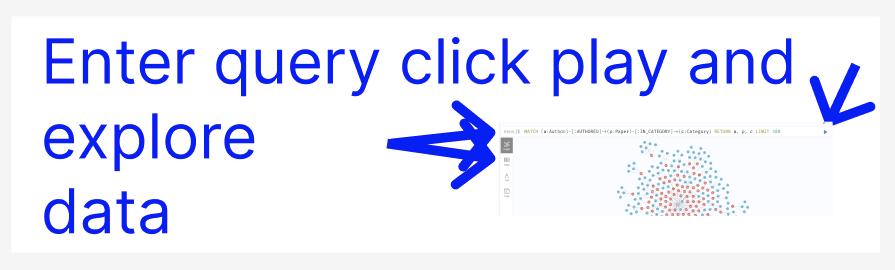
- Try another using the "where" clause to limit to "CS" papers:

`
    MATCH (a:Author)-[:AUTHORED]->(p:Paper)-[:IN_CATEGORY]->(c:Category)  
    RETURN a, p, c limit 50  
    union all  
    MATCH (a:Author)-[:AUTHORED]->(p:Paper)-[:IN_CATEGORY]->(c:Category)   
    where c.category starts with "cs"  
    RETURN a, p, c limit 50  
`
 - Try dragging the center node around :)
 - Explain to someone what this query asks and show them what the resulting graph looks like:
`
    MATCH (c:Category)--(p2:Paper)--(a2:Author)--(p3:Paper)--(c2:Category)
    where c<>c2
    RETURN c,p2,a2,p3,c2 limit 300
`

In [15]:
# (Run this and read to understand)
# List the count of papers in each category!

query_string = '''
MATCH (c:Category)
RETURN c.category, apoc.node.degree(c, "<IN_CATEGORY") AS inDegree
ORDER BY inDegree DESC LIMIT 20
'''

top_cat_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
top_cat_df.head(20)

,c.category,inDegree
0,astro-ph,19697
1,hep-ph,9506
2,hep-th,8857
3,quant-ph,6279
4,gr-qc,5282
5,cond-mat.mtrl-sci,4553
6,cond-mat.stat-mech,4380
7,cond-mat.str-el,4344
8,math.MP,4334
9,math-ph,4334


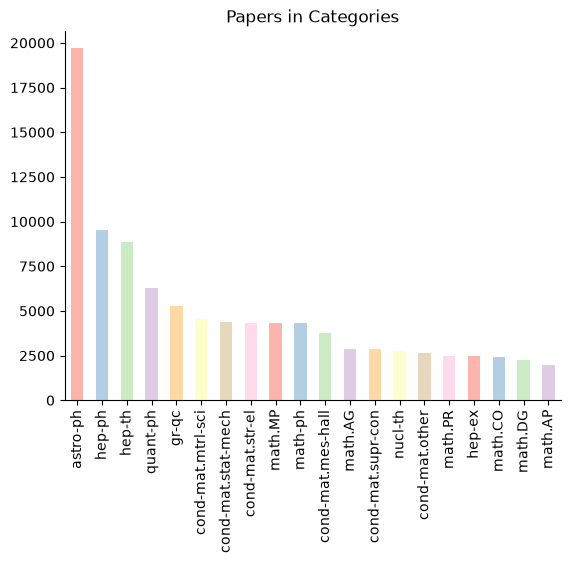

In [16]:
# (Run this and read to understand)
# Graph it in a bar plot
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colormaps
top_cat_df.plot.bar(y = "inDegree", x = "c.category", xlabel="", title="Papers in Categories", legend=None, color=plt.cm.Pastel1(np.arange(8)))
plt.gca().spines[['top', 'right',]].set_visible(False)
plt.savefig("indegree_by_category.png", bbox_inches="tight", dpi=150)
plt.show()


In [17]:
# Can you show the indegree of just computer science type category papers?

# WHERE ... STARTS WITH 'cs.' keeps only computer-science categories (cs.AI, cs.LG, ...)
# apoc.node.degree(c, "<IN_CATEGORY") counts the IN_CATEGORY relationships pointing INTO c (= papers in c)
query_string = '''
MATCH (c:Category)
WHERE c.category STARTS WITH 'cs.'
RETURN c.category, apoc.node.degree(c, "<IN_CATEGORY") AS inDegree
ORDER BY inDegree DESC
'''

cs_cat_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
print(f"{len(cs_cat_df)} CS categories")
cs_cat_df


40 CS categories


,c.category,inDegree
0,cs.IT,1487
1,cs.DM,504
2,cs.DS,474
3,cs.AI,428
4,cs.NI,425
5,cs.CC,410
6,cs.LO,390
7,cs.CR,312
8,cs.OH,303
9,cs.DC,239


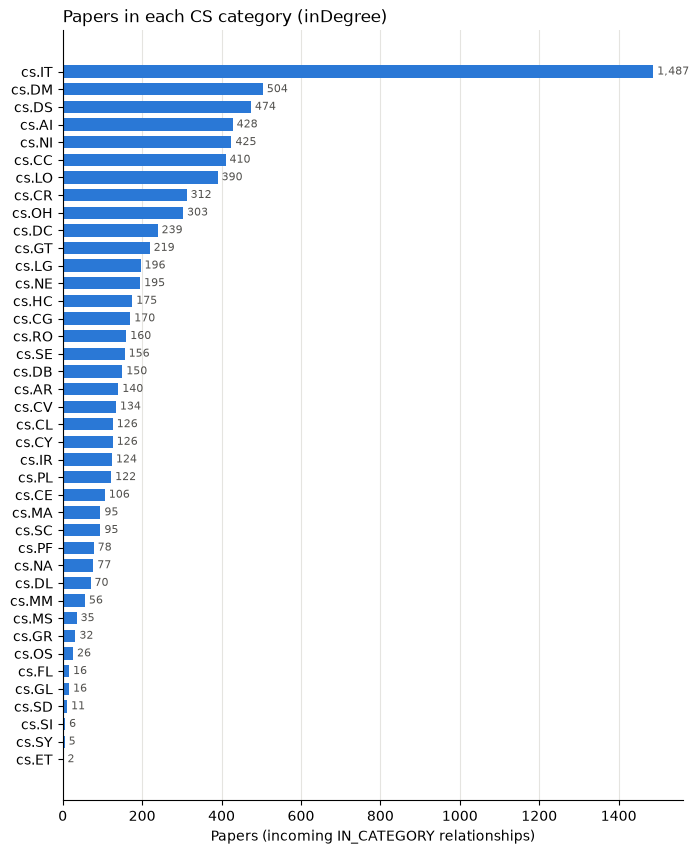

In [18]:
# Bar chart of papers per CS category (horizontal so the ~40 labels stay readable)
plot_df = cs_cat_df.sort_values("inDegree")
fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(plot_df["c.category"], plot_df["inDegree"], color="#2a78d6", height=0.7)
for y, v in enumerate(plot_df["inDegree"]):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8, color="#52514e")
ax.set_title("Papers in each CS category (inDegree)", loc="left")
ax.set_xlabel("Papers (incoming IN_CATEGORY relationships)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
plt.savefig("indegree_cs_categories.png", bbox_inches="tight", dpi=150)
plt.show()


### Sanity check: is `'cs.'` the right prefix?
List every category that starts with just `'cs'` (no dot). If something like a non-CS category also started with `cs`, it would show up here with a `False` in the `isCsDot` column.

In [19]:
query_string = '''
MATCH (c:Category)
WHERE c.category STARTS WITH 'cs'
RETURN c.category AS category, c.category STARTS WITH 'cs.' AS isCsDot
ORDER BY category
'''
prefix_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
print(f"{len(prefix_df)} categories start with 'cs'; {(~prefix_df.isCsDot).sum()} of them do NOT start with 'cs.'")
print(", ".join(prefix_df.category))


40 categories start with 'cs'; 0 of them do NOT start with 'cs.'
cs.AI, cs.AR, cs.CC, cs.CE, cs.CG, cs.CL, cs.CR, cs.CV, cs.CY, cs.DB, cs.DC, cs.DL, cs.DM, cs.DS, cs.ET, cs.FL, cs.GL, cs.GR, cs.GT, cs.HC, cs.IR, cs.IT, cs.LG, cs.LO, cs.MA, cs.MM, cs.MS, cs.NA, cs.NE, cs.NI, cs.OH, cs.OS, cs.PF, cs.PL, cs.RO, cs.SC, cs.SD, cs.SE, cs.SI, cs.SY


In [20]:
# Write an aggregate query to count all papers
# https://neo4j.com/docs/cypher-manual/current/functions/aggregating/

# count(p) is an aggregating function: it collapses all matched Paper rows into one number
query_string = '''
MATCH (p:Paper)
RETURN count(p) AS totalPapers
'''
total_papers = conn.query(query_string)[0]["totalPapers"]
print(f"Total papers: {total_papers:,}")


Total papers: 100,000


In [21]:
# Write a query to sum or count the total number of papers in CS type categories

# (A) OFFICIAL ANSWER - unique papers that are in at least one CS category.
#     A paper cross-listed in cs.AI and cs.LG matches twice, but count(DISTINCT p) counts it once.
query_unique = '''
MATCH (p:Paper)-[:IN_CATEGORY]->(c:Category)
WHERE c.category STARTS WITH 'cs.'
RETURN count(DISTINCT p) AS uniqueCsPapers
'''

# (B) Paper-category memberships - a paper in cs.AI and cs.LG counts twice.
query_memberships = '''
MATCH (p:Paper)-[:IN_CATEGORY]->(c:Category)
WHERE c.category STARTS WITH 'cs.'
RETURN count(p) AS csCategoryMemberships
'''

# (C) Same as (B) but via APOC: add up the inDegree of every CS category with sum()
query_sum_degree = '''
MATCH (c:Category)
WHERE c.category STARTS WITH 'cs.'
RETURN sum(apoc.node.degree(c, "<IN_CATEGORY")) AS sumCsInDegree
'''

unique_cs = conn.query(query_unique)[0]["uniqueCsPapers"]
memberships_cs = conn.query(query_memberships)[0]["csCategoryMemberships"]
sum_degree_cs = conn.query(query_sum_degree)[0]["sumCsInDegree"]

print(f"(A) Unique CS papers (OFFICIAL):          {unique_cs:,}")
print(f"(B) CS paper-category memberships:        {memberships_cs:,}")
print(f"(C) sum of CS category inDegrees (APOC):  {sum_degree_cs:,}")
print(f"(B) == (C)? {memberships_cs == sum_degree_cs}")
print(f"Difference (B) - (A): {memberships_cs - unique_cs:,} extra counts from papers cross-listed in 2+ CS categories")


(A) Unique CS papers (OFFICIAL):          5,812
(B) CS paper-category memberships:        7,891
(C) sum of CS category inDegrees (APOC):  7,891
(B) == (C)? True
Difference (B) - (A): 2,079 extra counts from papers cross-listed in 2+ CS categories


In [22]:
# How many CS categories is each CS paper in? (explains the gap between A and B)
query_string = '''
MATCH (p:Paper)-[:IN_CATEGORY]->(c:Category)
WHERE c.category STARTS WITH 'cs.'
WITH p, count(c) AS numCsCategories
RETURN numCsCategories, count(p) AS papers
ORDER BY numCsCategories
'''
crosslist_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
crosslist_df["contributes_to_B"] = crosslist_df.numCsCategories * crosslist_df.papers
print(crosslist_df.to_string(index=False))
print("sum(papers) =", crosslist_df.papers.sum(), " sum(contributes_to_B) =", crosslist_df.contributes_to_B.sum())


 numCsCategories  papers  contributes_to_B
               1    4020              4020
               2    1551              3102
               3     205               615
               4      29               116
               5       5                25
               6       1                 6
               7       1                 7
sum(papers) = 5812  sum(contributes_to_B) = 7891


### Unique papers vs. per-category counts

- **(A) `count(DISTINCT p)` is the official answer**: the number of *unique papers* that appear in at least one CS category.
- **(B) `count(p)`** counts *rows* of the pattern `(p)-[:IN_CATEGORY]->(c)`. The pattern produces one row per paper-category relationship, so a paper cross-listed in `cs.AI` **and** `cs.LG` is counted **twice**. This number is really "CS category memberships," not papers.
- **(C) `sum(apoc.node.degree(...))`** adds up the bar heights from the CS bar chart. Every bar counts each of its papers, so cross-listed papers are again counted once per CS category, and (C) equals (B).
- The difference (B) − (A) is exactly the extra counts from papers in 2+ CS categories (see the table above: Σ papers = A, Σ numCsCategories × papers = B).
- Why Cypher behaves this way: `MATCH` returns **every** way the pattern can match, and aggregation runs over those rows. `DISTINCT` deduplicates before counting.


# Something fun
### 1. Which pairs of CS categories show up together on the same paper most often?

In [23]:
# Two IN_CATEGORY relationships from the same paper p to two different CS categories.
# c1.category < c2.category keeps each unordered pair once (no (A,B)+(B,A) double counting, no (A,A)).
query_string = '''
MATCH (c1:Category)<-[:IN_CATEGORY]-(p:Paper)-[:IN_CATEGORY]->(c2:Category)
WHERE c1.category STARTS WITH 'cs.' AND c2.category STARTS WITH 'cs.'
  AND c1.category < c2.category
RETURN c1.category AS category1, c2.category AS category2, count(p) AS sharedPapers
ORDER BY sharedPapers DESC LIMIT 10
'''
cs_pairs_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
cs_pairs_df.to_csv("fun_cs_category_pairs.csv", index=False)
cs_pairs_df


,category1,category2,sharedPapers
0,cs.DM,cs.DS,104
1,cs.CC,cs.DM,70
2,cs.CC,cs.DS,70
3,cs.IT,cs.NI,58
4,cs.DM,cs.IT,56
5,cs.AI,cs.NE,56
6,cs.CC,cs.LO,55
7,cs.AI,cs.LG,52
8,cs.DC,cs.NI,45
9,cs.CR,cs.IT,43


**What this shows:** the strongest CS pairing is `cs.DM` (discrete math) + `cs.DS` (data structures & algorithms), and the top three pairs are all theory (DM / DS / CC = computational complexity). `cs.AI` + `cs.LG` is only 8th. That makes sense because this sample is arXiv papers from **April 2007 to December 2008** (ids `0704.*`-`0812.*`), years before deep learning made `cs.LG` the biggest category on arXiv.

### 2. Who are the most prolific authors, and how many distinct co-authors do they have?

In [24]:
# Out-degree of AUTHORED = number of papers; then walk Author->Paper<-Author to collect co-authors.
query_string = '''
MATCH (a:Author)-[:AUTHORED]->(p:Paper)
WITH a, count(p) AS papers
ORDER BY papers DESC LIMIT 10
OPTIONAL MATCH (a)-[:AUTHORED]->(:Paper)<-[:AUTHORED]-(co:Author)
WHERE co <> a
RETURN a.name AS author, papers, count(DISTINCT co) AS distinctCoauthors
ORDER BY papers DESC, distinctCoauthors DESC
'''
prolific_df = pd.DataFrame([dict(_) for _ in conn.query(query_string)])
prolific_df.to_csv("fun_prolific_authors.csv", index=False)
prolific_df


,author,papers,distinctCoauthors
0,B. Aubert,133,5
1,The BABAR Collaboration,119,3
2,H. Vincent Poor,105,97
3,Damien Chablat,99,47
4,D0 Collaboration,73,16
5,Philippe Wenger,70,20
6,CDF Collaboration,69,20
7,S. Das Sarma,64,76
8,N. Gehrels,63,541
9,T. Aaltonen,54,5


**What this shows:** "most papers" is not the same as "most collaborators". `B. Aubert` has 133 papers but only 5 distinct co-authors, because huge particle-physics collaborations (BaBar) list papers as *"B. Aubert et al."* or under a collaboration name. N. Gehrels (NASA Swift/Fermi) has 63 papers but 541 co-authors. Some "authors" are not even people (`The BABAR Collaboration`, `D0 Collaboration`), a data-cleaning issue a real project would fix.

**Bonus observation:** `cs.IT` is by far the biggest CS bar (1,487 papers) because every `cs.IT` paper is also tagged `math.IT`; arXiv treats them as aliases of the same Information Theory archive. Likewise `math.MP` and `math-ph` have identical counts (4,334) in the top-20 chart.